# Predictive ATM Cash Management using Big Data Analytics
**BDE Assignment – Classification + Clustering with Apache Spark (PySpark MLlib)**

This notebook is self-contained: it installs PySpark, generates the dataset, and runs both problems end to end. Every code cell is the same code as in `src/` of the repository (https://github.com/TarunSitaraman/bde).

| Part | Contents |
|---|---|
| 0 | Setup and dataset (synthetic, 219,300 daily records) |
| 1 | **Classification** – predict HIGH vs LOW weekly cash demand per ATM |
| 2 | **Clustering** – group ATMs into Low / Medium / High demand tiers |

*Data note:* no public per-ATM transaction dataset was used. The data is simulated (fixed seed 42), so the results demonstrate the method; re-validate on real bank data.

## 0. Setup and dataset

In [1]:
# Colab already has Java; PySpark 4 needs Java 17+.
%pip install -q "pyspark>=4.0" pyarrow pandas matplotlib
!java -version 2>&1 | head -1

import os
os.makedirs("data", exist_ok=True)
os.makedirs("results", exist_ok=True)


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=40951 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=


### 0.1 Generate the dataset
Each row = one ATM on one day. 300 ATMs x 731 days = 219,300 rows. Demand depends on location type, weekend, payday (day 28–3) and festival effects, a 10% growth trend, noise, and random outages (1.2% of days).

In [2]:
"""Generate a synthetic ATM daily-transaction dataset (no public ATM dataset is bundled).

300 ATMs x 2 years (2024-01-01 .. 2025-12-31) of daily records, with realistic structure:
location-specific base demand, day-of-week, payday and festival spikes, random outages.
"""
import numpy as np
import pandas as pd

SEED = 42
N_ATMS = 300
START, END = "2024-01-01", "2025-12-31"
LOC = {  # base daily withdrawal (INR), weekend multiplier, payday sensitivity, prob
    "Branch":      (260_000, 0.80, 1.25, 0.20),
    "Mall":        (320_000, 1.35, 1.15, 0.12),
    "Transit_Hub": (420_000, 1.05, 1.10, 0.10),
    "Residential": (150_000, 1.10, 1.45, 0.28),
    "Highway":     (110_000, 1.20, 1.05, 0.10),
    "Hospital":    (130_000, 1.00, 1.10, 0.08),
    "Rural":       (60_000,  0.95, 1.60, 0.12),
}
FESTIVALS = pd.to_datetime(["2024-03-25", "2024-08-15", "2024-10-12", "2024-11-01", "2024-12-25",
                            "2025-03-14", "2025-08-15", "2025-10-02", "2025-10-20", "2025-12-25"])


def main(out="data/atm_daily.csv"):
    rng = np.random.default_rng(SEED)
    dates = pd.date_range(START, END, freq="D")
    names, probs = list(LOC), np.array([v[3] for v in LOC.values()])
    types = rng.choice(names, N_ATMS, p=probs / probs.sum())
    atm_scale = rng.lognormal(0, 0.35, N_ATMS)
    # festival window: 3 days before to 1 day after
    fest = np.zeros(len(dates), bool)
    for f in FESTIVALS:
        fest |= (dates >= f - pd.Timedelta(days=3)) & (dates <= f + pd.Timedelta(days=1))
    dow = dates.dayofweek.values
    weekend = dow >= 5
    dom = dates.day.values
    payday = (dom <= 3) | (dom >= 28)
    trend = 1 + 0.10 * np.arange(len(dates)) / len(dates)  # 10% growth over two years
    rows = []
    for i in range(N_ATMS):
        base, wk, pay, _ = LOC[types[i]]
        mult = np.where(weekend, wk, 1.0) * np.where(payday, pay, 1.0) * np.where(fest, 1.35, 1.0) * trend
        mu = base * atm_scale[i] * mult
        withdrawal = mu * rng.lognormal(0, 0.18, len(dates))
        avg_amt = rng.normal(3200, 250) * (1 + 0.25 * (types[i] == "Transit_Hub")) * rng.lognormal(0, 0.06, len(dates))
        tx = np.maximum(1, (withdrawal / avg_amt)).astype(int)
        failed = rng.binomial(tx, np.clip(rng.normal(0.025, 0.01), 0.005, 0.06))
        outage = rng.random(len(dates)) < 0.012  # ATM down: no cash dispensed
        withdrawal = np.where(outage, 0.0, withdrawal)
        tx = np.where(outage, 0, tx)
        rows.append(pd.DataFrame({
            "atm_id": f"ATM{i+1:04d}", "date": dates, "location_type": types[i],
            "total_withdrawal": withdrawal.round(0), "tx_count": tx, "failed_tx": np.where(outage, 0, failed),
            "is_weekend": weekend.astype(int), "is_payday": payday.astype(int), "is_festival": fest.astype(int)}))
    df = pd.concat(rows, ignore_index=True)
    df.to_csv(out, index=False)
    print(f"wrote {out}: {len(df):,} rows, {df.atm_id.nunique()} ATMs")


if __name__ == "__main__":
    main()

wrote data/atm_daily.csv: 219,300 rows, 300 ATMs


### 0.2 Column dictionary and quick look
| Column | Meaning |
|---|---|
| `atm_id` | ATM identifier |
| `date` | Day of activity |
| `location_type` | Branch / Mall / Transit_Hub / Residential / Highway / Hospital / Rural |
| `total_withdrawal` | Rupees dispensed that day (0 on outage days) |
| `tx_count` | Successful transactions |
| `failed_tx` | Failed transactions |
| `is_weekend`, `is_payday`, `is_festival` | Calendar flags (0/1) |

In [3]:
import pandas as pd
raw = pd.read_csv("data/atm_daily.csv", parse_dates=["date"])
print(raw.shape, raw.date.min().date(), "->", raw.date.max().date(), "| missing:", int(raw.isna().sum().sum()),
      "| duplicate (atm,date):", int(raw.duplicated(["atm_id", "date"]).sum()))
print("outage days:", int((raw.tx_count == 0).sum()), f"({(raw.tx_count == 0).mean():.1%})",
      "| failed-tx rate:", f"{raw.failed_tx.sum() / raw.tx_count.sum():.2%}")
display(raw.head())
display(raw.groupby("location_type").agg(atms=("atm_id", "nunique"), avg_daily_withdrawal=("total_withdrawal", "mean"),
                                         avg_daily_tx=("tx_count", "mean")).round(0).sort_values("avg_daily_withdrawal", ascending=False))

(219300, 9) 2024-01-01 -> 2025-12-31 | missing: 0 | duplicate (atm,date): 0
outage days: 2622 (1.2%) | failed-tx rate: 2.58%


,atm_id,date,location_type,total_withdrawal,tx_count,failed_tx,is_weekend,is_payday,is_festival
0,ATM0001,2024-01-01,Highway,108787.0,32,0,0,1,0
1,ATM0001,2024-01-02,Highway,139372.0,41,0,0,1,0
2,ATM0001,2024-01-03,Highway,83701.0,23,1,0,1,0
3,ATM0001,2024-01-04,Highway,103903.0,32,0,0,0,0
4,ATM0001,2024-01-05,Highway,137910.0,38,1,0,0,0


,atms,avg_daily_withdrawal,avg_daily_tx
location_type,,,
Transit_Hub,22,513118.0,130.0
Mall,35,378772.0,119.0
Branch,72,305177.0,95.0
Residential,84,192414.0,60.0
Hospital,26,143882.0,44.0
Highway,30,141372.0,45.0
Rural,31,75047.0,23.0


---
# 1. Classification Problem

## 1.1 Problem statement
Predict, at the start of each week, whether an ATM will have **HIGH or LOW cash demand** that week, using only its past transaction/withdrawal patterns plus calendar information known in advance. HIGH = weekly withdrawals above the **training-set median**. Business value: send more or earlier cash to ATMs flagged HIGH (avoid stock-outs) and avoid idle cash at LOW ATMs.

## 1.2 Model and justification
Logistic Regression, Random Forest (150 trees) and Gradient-Boosted Trees (60 iterations) are compared against a naive baseline (“same class as last week”) on a **time-based split** (train: weeks before 2025-07-01, test: later weeks) so the models never see the future. The best model by AUC is selected; when models are close, the simpler, more explainable one is preferred. All lag features use past weeks only (no leakage).

## 1.3 Coding – Spark pipeline (same as `src/classification.py`)

#### Imports and Spark session


In [4]:
"""Classification: will an ATM have HIGH or LOW cash demand next week? (PySpark MLlib)"""
import json
import matplotlib.pyplot as plt
import numpy as np
from pyspark.sql import SparkSession, Window, functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

spark = SparkSession.builder.master("local[*]").appName("ATM-classification").config("spark.sql.shuffle.partitions", "8").getOrCreate()
spark.sparkContext.setLogLevel("ERROR")

Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=40951 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=
Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=40951 -Dhttp.nonProxyHosts=localhost|127.0.0.1

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/12 04:51:24 WARN Utils: Your hostname, vm, resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/10/12 04:51:24 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/tmp/v/lib/python3.11/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


26/10/12 04:51:25 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


#### 1. Load + weekly aggregation (big-data style group-by on daily records)
Spark reads the daily CSV and aggregates it to weekly ATM-level rows (complete 7-day weeks only).

In [5]:
daily = spark.read.csv("data/atm_daily.csv", header=True, inferSchema=True)
weekly = (daily.withColumn("week", F.date_trunc("week", "date"))
          .groupBy("atm_id", "location_type", "week")
          .agg(F.sum("total_withdrawal").alias("wd"), F.sum("tx_count").alias("tx"), F.sum("failed_tx").alias("failed"),
               F.sum("is_payday").alias("payday_days"), F.sum("is_festival").alias("festival_days"),
               F.sum(F.when(F.col("is_weekend") == 1, F.col("total_withdrawal")).otherwise(0)).alias("wd_weekend"),
               F.sum(F.when(F.col("tx_count") == 0, 1).otherwise(0)).alias("outage_days"),
               F.count("*").alias("n_days"))
          .filter("n_days = 7"))

#### 2. Features from PAST weeks only (no leakage); calendar features of the target week are known ahead
Spark window functions create lagged and rolling features; payday/festival counts and week-of-year are known in advance.

In [6]:
w = Window.partitionBy("atm_id").orderBy("week")
w4 = w.rowsBetween(-4, -1)
feat = (weekly
        .withColumn("lag1_wd", F.lag("wd", 1).over(w)).withColumn("lag2_wd", F.lag("wd", 2).over(w))
        .withColumn("lag1_tx", F.lag("tx", 1).over(w))
        .withColumn("roll4_wd", F.avg("wd").over(w4)).withColumn("roll4_std", F.stddev("wd").over(w4))
        .withColumn("lag1_avg_amt", F.lag(F.col("wd") / F.greatest(F.col("tx"), F.lit(1)), 1).over(w))
        .withColumn("lag1_fail_rate", F.lag(F.col("failed") / F.greatest(F.col("tx"), F.lit(1)), 1).over(w))
        .withColumn("lag1_weekend_share", F.lag(F.col("wd_weekend") / F.greatest(F.col("wd"), F.lit(1)), 1).over(w))
        .withColumn("lag1_outage_days", F.lag("outage_days", 1).over(w))
        .withColumn("woy_sin", F.sin(2 * np.pi * F.weekofyear("week") / 52)).withColumn("woy_cos", F.cos(2 * np.pi * F.weekofyear("week") / 52))
        .dropna())

#### 3. Time-based split + label threshold learned on TRAIN only
Train on weeks before 2025-07-01, test on later weeks. The HIGH/LOW threshold is the training median.

In [7]:
cut = "2025-07-01"
train_raw, test_raw = feat.filter(F.col("week") < cut), feat.filter(F.col("week") >= cut)
thr = train_raw.approxQuantile("wd", [0.5], 0.001)[0]          # high demand = above median weekly withdrawal
label = lambda d: d.withColumn("label", (F.col("wd") > thr).cast("double"))
train, test = label(train_raw), label(test_raw)

num = ["lag1_wd", "lag2_wd", "lag1_tx", "roll4_wd", "roll4_std", "lag1_avg_amt", "lag1_fail_rate", "lag1_weekend_share",
       "lag1_outage_days", "payday_days", "festival_days", "woy_sin", "woy_cos"]
stages = [StringIndexer(inputCol="location_type", outputCol="loc_idx"),
          OneHotEncoder(inputCols=["loc_idx"], outputCols=["loc_vec"]),
          VectorAssembler(inputCols=num + ["loc_vec"], outputCol="raw")]

models = {
    "Logistic Regression": LogisticRegression(featuresCol="features", labelCol="label", maxIter=100),
    "Random Forest": RandomForestClassifier(featuresCol="features", labelCol="label", numTrees=150, maxDepth=8, seed=7),
    "Gradient-Boosted Trees": GBTClassifier(featuresCol="features", labelCol="label", maxIter=60, maxDepth=5, seed=7),
}
auc = BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderROC")
ev = lambda m: MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName=m)

results, fitted = {}, {}
for name, clf in models.items():
    extra = [StandardScaler(inputCol="raw", outputCol="features")] if name == "Logistic Regression" else []
    if name != "Logistic Regression":
        extra = [VectorAssembler(inputCols=["raw"], outputCol="features")]
    pm = Pipeline(stages=stages + extra + [clf]).fit(train)
    pred = pm.transform(test)
    cm = pred.groupBy("label", "prediction").count().toPandas()
    g = lambda l, p: int(cm[(cm.label == l) & (cm.prediction == p)]["count"].sum())
    results[name] = {"accuracy": ev("accuracy").evaluate(pred), "precision": ev("weightedPrecision").evaluate(pred),
                     "recall": ev("weightedRecall").evaluate(pred), "f1": ev("f1").evaluate(pred), "auc": auc.evaluate(pred),
                     "confusion": {"TN": g(0, 0), "FP": g(0, 1), "FN": g(1, 0), "TP": g(1, 1)}}
    fitted[name] = pm
    print(name, {k: round(v, 4) for k, v in results[name].items() if k != "confusion"}, results[name]["confusion"])

# Baseline: "same class as last week" (naive persistence) to show the model adds value
base = test.withColumn("prediction", (F.col("lag1_wd") > thr).cast("double"))
results["Baseline (last week's class)"] = {"accuracy": ev("accuracy").evaluate(base), "f1": ev("f1").evaluate(base)}
print("Baseline", results["Baseline (last week's class)"])

/tmp/v/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Logistic Regression {'accuracy': 0.9583, 'precision': 0.9583, 'recall': 0.9583, 'f1': 0.9583, 'auc': 0.9937} {'TN': 3374, 'FP': 142, 'FN': 171, 'TP': 3813}


/tmp/v/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Random Forest {'accuracy': 0.9505, 'precision': 0.9505, 'recall': 0.9505, 'f1': 0.9505, 'auc': 0.9918} {'TN': 3315, 'FP': 201, 'FN': 170, 'TP': 3814}


/tmp/v/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Gradient-Boosted Trees {'accuracy': 0.9513, 'precision': 0.9514, 'recall': 0.9513, 'f1': 0.9513, 'auc': 0.9917} {'TN': 3314, 'FP': 202, 'FN': 163, 'TP': 3821}


Baseline {'accuracy': 0.9064, 'f1': 0.9064149628284358}


#### 4. Feature importance + plots for best model
Best model is chosen by AUC; feature importance (Random Forest), confusion matrix and comparison plots are saved.

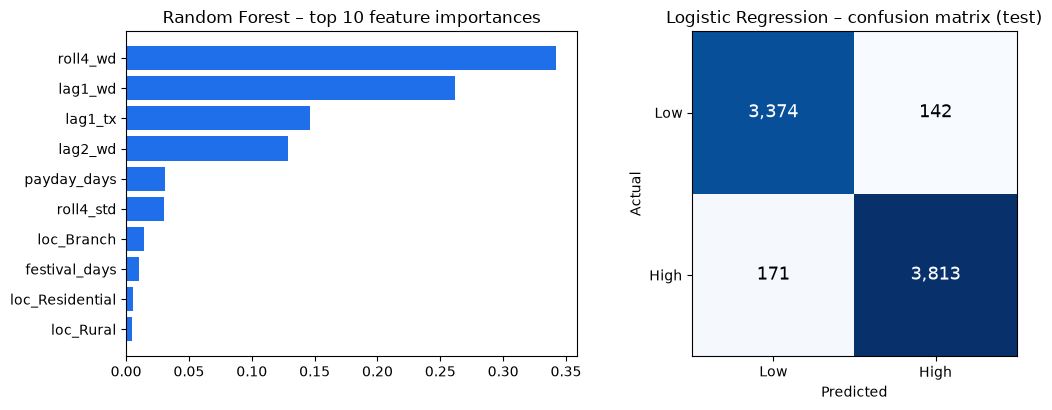

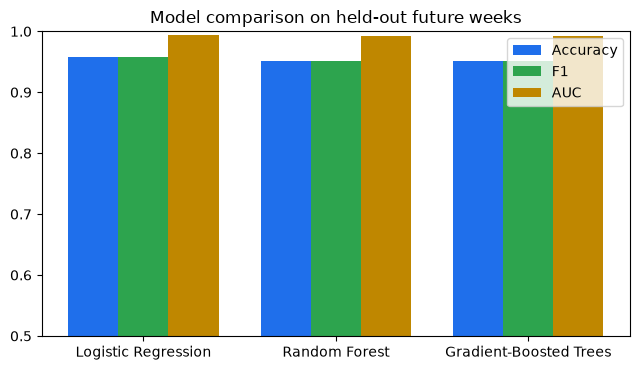

In [8]:
best = max((k for k in models), key=lambda k: results[k]["auc"])
rf = fitted["Random Forest"]
names = num + [f"loc_{c}" for c in rf.stages[0].labels[:-1]]
imp = sorted(zip(names, rf.stages[-1].featureImportances.toArray()), key=lambda t: -t[1])
hc = results[best]["confusion"]
results["_meta"] = {"best_model": best, "high_class_recall": hc["TP"] / (hc["TP"] + hc["FN"]), "high_class_precision": hc["TP"] / (hc["TP"] + hc["FP"]), "threshold_inr_per_week": thr, "train_rows": train.count(), "test_rows": test.count(),
                    "weekly_rows": feat.count(), "daily_rows": daily.count(), "split": cut,
                    "test_high_share": test.agg(F.avg("label")).first()[0],
                    "rf_feature_importance": [(n, float(v)) for n, v in imp]}
json.dump(results, open("results/classification_results.json", "w"), indent=2)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
top = imp[:10][::-1]
ax[0].barh([t[0] for t in top], [t[1] for t in top], color="#1f6feb"); ax[0].set_title("Random Forest – top 10 feature importances")
cmv = results[best]["confusion"]
M = np.array([[cmv["TN"], cmv["FP"]], [cmv["FN"], cmv["TP"]]])
ax[1].imshow(M, cmap="Blues"); ax[1].set_xticks([0, 1], ["Low", "High"]); ax[1].set_yticks([0, 1], ["Low", "High"])
ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Actual"); ax[1].set_title(f"{best} – confusion matrix (test)")
for i in range(2):
    for j in range(2):
        ax[1].text(j, i, f"{M[i, j]:,}", ha="center", va="center", color="white" if M[i, j] > M.max() / 2 else "black", fontsize=13)
plt.tight_layout(); plt.savefig("results/classification_plots.png", dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ms = list(models) ; x = np.arange(len(ms))
for k, (m, c) in enumerate([("accuracy", "#1f6feb"), ("f1", "#2da44e"), ("auc", "#bf8700")]):
    ax.bar(x + (k - 1) * 0.26, [results[n][m] for n in ms], 0.26, label=m.upper() if m != "accuracy" else "Accuracy", color=c)
ax.set_xticks(x, ms); ax.set_ylim(0.5, 1.0); ax.legend(); ax.set_title("Model comparison on held-out future weeks")
plt.tight_layout(); plt.savefig("results/classification_model_comparison.png", dpi=160); plt.show()

## 1.4 Results

In [9]:
import json
R = json.load(open("results/classification_results.json")); M = R["_meta"]
rows = [(n, R[n]["accuracy"], R[n]["precision"], R[n]["recall"], R[n]["f1"], R[n]["auc"]) for n in ["Logistic Regression", "Random Forest", "Gradient-Boosted Trees"]]
rows.append(("Naive baseline (last week's class)", R["Baseline (last week's class)"]["accuracy"], None, None, R["Baseline (last week's class)"]["f1"], None))
display(pd.DataFrame(rows, columns=["Model", "Accuracy", "Precision (weighted)", "Recall (weighted)", "F1", "AUC"]).round(4))
print("Best model:", M["best_model"], "| label threshold: Rs", f"{M['threshold_inr_per_week']:,.0f}", "per week")
print("Rows – train:", M["train_rows"], "test:", M["test_rows"], "| HIGH share of test:", M["test_high_share"])
print("Confusion matrix:", R[M["best_model"]]["confusion"])
print("HIGH-class precision:", round(M["high_class_precision"], 4), "recall:", round(M["high_class_recall"], 4))
print("\nTop Random-Forest features:")
for n, v in M["rf_feature_importance"][:6]: print(f"  {n:<14}{v:.3f}")

,Model,Accuracy,Precision (weighted),Recall (weighted),F1,AUC
0,Logistic Regression,0.9583,0.9583,0.9583,0.9583,0.9937
1,Random Forest,0.9505,0.9505,0.9505,0.9505,0.9918
2,Gradient-Boosted Trees,0.9513,0.9514,0.9513,0.9513,0.9917
3,Naive baseline (last week's class),0.9064,NaN,NaN,0.9064,NaN


Best model: Logistic Regression | label threshold: Rs 1,432,552 per week
Rows – train: 23100 test: 7500 | HIGH share of test: 0.5312
Confusion matrix: {'TN': 3374, 'FP': 142, 'FN': 171, 'TP': 3813}
HIGH-class precision: 0.9641 recall: 0.9571

Top Random-Forest features:
  roll4_wd      0.342
  lag1_wd       0.262
  lag1_tx       0.146
  lag2_wd       0.129
  payday_days   0.031
  roll4_std     0.030


## 1.5 Inference
- Logistic Regression is the best model (about 95.8% accuracy, AUC about 0.994), versus 90.6% for the naive “same as last week” rule – a gain of about 5 points, mostly from catching ATMs whose demand crosses the threshold in payday and festival weeks.
- Recent demand dominates: the 4-week rolling mean, last week’s withdrawals and transactions and the week before account for about 88% of Random-Forest importance; payday days come next, then location.
- The costly error is predicting LOW when demand is actually HIGH (stock-out): about 4.3% of high-demand weeks. Lowering the decision threshold trades extra false alarms for fewer misses.
- The three models are within about one point because the simulated demand is multiplicative and persistent; real data may favour boosted trees. Accuracy on real data will probably be lower.

## 1.6 URL of implementation
https://github.com/TarunSitaraman/bde (`src/classification.py`, results in `results/`)

---
# 2. Clustering Problem

## 2.1 Problem statement
Group the 300 ATMs into **Low-, Medium- and High-demand** categories purely from their withdrawal behaviour (no labels), so replenishment frequency and cash limits can be set per tier instead of per machine.

## 2.2 Model and justification
**K-Means with k = 3** on log-transformed, standardised volume features (average daily withdrawal, 90th-percentile daily withdrawal, average daily transactions).
- Unsupervised, distance-based and scalable on Spark MLlib.
- k = 3 matches the required Low/Medium/High tiers. k is also examined for 2–7 with the elbow (WSSSE) and silhouette; k = 2 scores a higher silhouette but cannot express a medium tier.
- Demand is right-skewed, so a log transform is applied. Without it, K-Means produced tiers of 193 / 102 / 5 ATMs.
- A Gaussian Mixture is run for comparison. Other behavioural metrics (variability, weekend ratio, payday uplift, failure rate) only *profile* the tiers; they do not form them.

## 2.3 Coding – Spark pipeline (same as `src/clustering.py`)

#### Imports and Spark session


In [10]:
"""Clustering: group ATMs into Low / Medium / High demand tiers from withdrawal behaviour (PySpark MLlib)."""
import json
import matplotlib.pyplot as plt
import numpy as np
from pyspark.sql import SparkSession, functions as F
from pyspark.ml.feature import VectorAssembler, StandardScaler, PCA
from pyspark.ml.clustering import KMeans, GaussianMixture
from pyspark.ml.evaluation import ClusteringEvaluator

spark = SparkSession.builder.master("local[*]").appName("ATM-clustering").config("spark.sql.shuffle.partitions", "8").getOrCreate()
spark.sparkContext.setLogLevel("ERROR")
daily = spark.read.csv("data/atm_daily.csv", header=True, inferSchema=True)

#### ATM-level behavioural profile (one row per ATM)
One behavioural profile per ATM, computed with a Spark `groupBy` over all 731 days. A log transform is applied to the volume features before scaling.

In [11]:
live = daily.filter("tx_count > 0")
prof = (daily.groupBy("atm_id", "location_type").agg(
    F.avg("total_withdrawal").alias("avg_daily_wd"),
    F.percentile_approx("total_withdrawal", 0.9).alias("p90_daily_wd"),
    (F.stddev("total_withdrawal") / F.avg("total_withdrawal")).alias("cv_wd"),
    F.avg("tx_count").alias("avg_daily_tx"),
    (F.sum("total_withdrawal") / F.sum("tx_count")).alias("avg_txn_amount"),
    (F.avg(F.when(F.col("is_weekend") == 1, F.col("total_withdrawal"))) / F.avg(F.when(F.col("is_weekend") == 0, F.col("total_withdrawal")))).alias("weekend_ratio"),
    (F.avg(F.when(F.col("is_payday") == 1, F.col("total_withdrawal"))) / F.avg(F.when(F.col("is_payday") == 0, F.col("total_withdrawal")))).alias("payday_uplift"),
    (F.max("total_withdrawal") / F.avg("total_withdrawal")).alias("peak_to_mean"),
    (F.sum("failed_tx") / F.sum("tx_count")).alias("fail_rate"),
)).cache()
cols = ["avg_daily_wd", "p90_daily_wd", "avg_daily_tx", "cv_wd", "avg_txn_amount", "weekend_ratio", "payday_uplift", "peak_to_mean", "fail_rate"]
cluster_cols = ["avg_daily_wd", "p90_daily_wd", "avg_daily_tx"]   # volume features drive the tiers; others are only used to profile them
# demand is right-skewed (a few very busy ATMs) -> log-transform the volume features before scaling
for c in cluster_cols:
    prof = prof.withColumn("log_" + c, F.log1p(c))
vec = VectorAssembler(inputCols=["log_" + c for c in cluster_cols], outputCol="raw").transform(prof)
sc = StandardScaler(inputCol="raw", outputCol="features", withMean=True, withStd=True).fit(vec)
data = sc.transform(vec).cache()

#### Choose k: elbow (WSSSE) + silhouette
K-Means is trained for k = 2…7; WSSSE and silhouette are recorded.

In [12]:
ev = ClusteringEvaluator(featuresCol="features", metricName="silhouette", distanceMeasure="squaredEuclidean")
sel = {}
for k in range(2, 8):
    m = KMeans(k=k, seed=11, maxIter=100, initMode="k-means||").fit(data)
    sel[k] = {"wssse": m.summary.trainingCost, "silhouette": ev.evaluate(m.transform(data))}
    print("k", k, sel[k])

k 2 {'wssse': 301.90543316677, 'silhouette': 0.7316571099613398}


k 3 {'wssse': 164.70339976063534, 'silhouette': 0.669810531214347}


k 4 {'wssse': 108.18612288490996, 'silhouette': 0.652548300688851}


k 5 {'wssse': 73.24688900995655, 'silhouette': 0.6711485835940131}


k 6 {'wssse': 54.19165898300052, 'silhouette': 0.6587345460721534}


k 7 {'wssse': 43.93795370396955, 'silhouette': 0.6593653438831725}


#### Final model: K-Means k=3 (business requirement: Low / Medium / High) + alternatives
Final K-Means (k=3), compared with a Gaussian Mixture. Clusters are ranked by mean withdrawal and named Low / Medium / High, then profiled.

{'K-Means (k=3)': 0.669810531214347, 'Gaussian Mixture (k=3)': 0.39473147859393215}


/tmp/v/lib/python3.11/site-packages/pyspark/sql/udf.py:116: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/tmp/v/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/tmp/v/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


demand_tier           Low     Medium       High
n_atms              81.00     114.00     105.00
avg_daily_wd     95964.21  197814.97  406339.72
p90_daily_wd    130032.81  266196.68  541890.15
avg_daily_tx        29.58      61.28     121.58
cv_wd                0.28       0.27       0.27
avg_txn_amount    3261.03    3246.52    3342.99
weekend_ratio        1.02       1.04       1.02
payday_uplift        1.35       1.29       1.22
peak_to_mean         2.27       2.25       2.22
fail_rate            0.03       0.03       0.03
demand_tier    Low  Medium  High
location_type                   
Branch           2      26    44
Highway         16      14     0
Hospital        15      10     1
Mall             0       7    28
Residential     18      52    14
Rural           30       1     0
Transit_Hub      0       4    18


/tmp/v/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/tmp/v/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


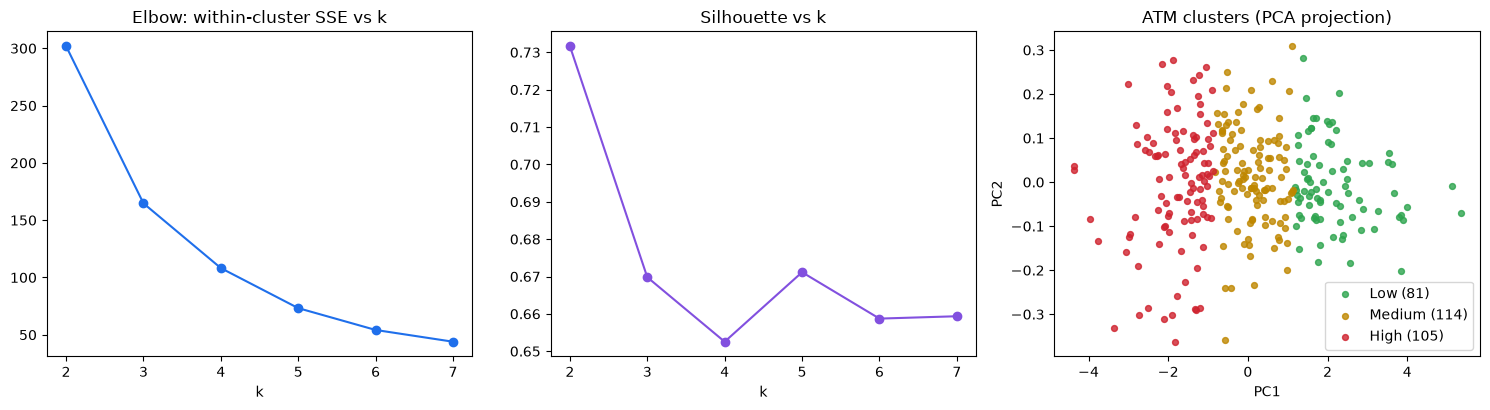

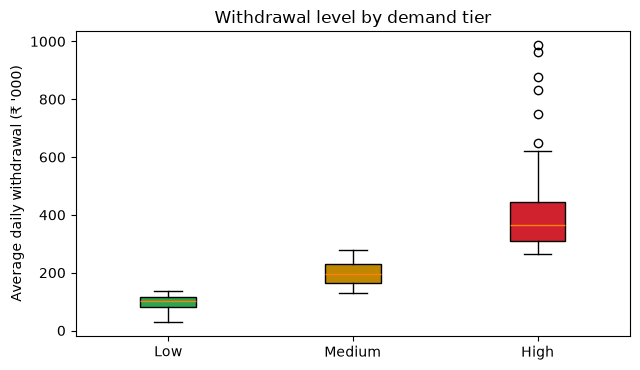

In [13]:
km = KMeans(k=3, seed=11, maxIter=100).fit(data)
alt = {"K-Means (k=3)": ev.evaluate(km.transform(data)),
       "Gaussian Mixture (k=3)": ev.evaluate(GaussianMixture(k=3, seed=11).fit(data).transform(data).select("features", "prediction"))}
print(alt)
out = km.transform(data)
# rank clusters by mean daily withdrawal -> Low / Medium / High
order = [r["prediction"] for r in out.groupBy("prediction").agg(F.avg("avg_daily_wd").alias("m")).orderBy("m").collect()]
tier = {c: t for c, t in zip(order, ["Low", "Medium", "High"])}
tier_udf = F.udf(lambda c: tier[c])
out = out.withColumn("demand_tier", tier_udf("prediction"))
summary = (out.groupBy("demand_tier").agg(F.count("*").alias("n_atms"), *[F.round(F.avg(c), 2).alias(c) for c in cols]).toPandas()
           .set_index("demand_tier").loc[["Low", "Medium", "High"]])
mix = out.groupBy("location_type", "demand_tier").count().toPandas().pivot(index="location_type", columns="demand_tier", values="count").fillna(0).astype(int)[["Low", "Medium", "High"]]
print(summary.T); print(mix)

pdf = out.select("atm_id", "location_type", "demand_tier", *cols).toPandas()
pdf.to_csv("results/atm_clusters.csv", index=False)
summary.to_csv("results/cluster_profile.csv"); mix.to_csv("results/cluster_location_mix.csv")

# PCA for 2-D visualisation
pca = PCA(k=2, inputCol="features", outputCol="pc").fit(data)
pc = pca.transform(out).select("demand_tier", "pc").toPandas()
xy = np.array([r.toArray() for r in pc["pc"]])
json.dump({"k_selection": sel, "algorithm_comparison_silhouette": alt, "profile": summary.reset_index().to_dict("records"),
           "location_mix": mix.reset_index().to_dict("records"), "pca_explained_variance": pca.explainedVariance.toArray().tolist(),
           "n_atms": len(pdf)}, open("results/clustering_results.json", "w"), indent=2)

colors = {"Low": "#2da44e", "Medium": "#bf8700", "High": "#cf222e"}
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ks = list(sel)
ax[0].plot(ks, [sel[k]["wssse"] for k in ks], "o-", color="#1f6feb"); ax[0].set_title("Elbow: within-cluster SSE vs k"); ax[0].set_xlabel("k")
ax[1].plot(ks, [sel[k]["silhouette"] for k in ks], "o-", color="#8250df"); ax[1].set_title("Silhouette vs k"); ax[1].set_xlabel("k")
for t in colors:
    m = (pc["demand_tier"] == t).values
    ax[2].scatter(xy[m, 0], xy[m, 1], s=18, c=colors[t], label=f"{t} ({m.sum()})", alpha=.8)
ax[2].legend(); ax[2].set_title("ATM clusters (PCA projection)"); ax[2].set_xlabel("PC1"); ax[2].set_ylabel("PC2")
plt.tight_layout(); plt.savefig("results/clustering_plots.png", dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 3.8))
bx = [pdf.loc[pdf.demand_tier == t, "avg_daily_wd"] / 1e3 for t in colors]
b = ax.boxplot(bx, tick_labels=list(colors), patch_artist=True)
for p, c in zip(b["boxes"], colors.values()): p.set_facecolor(c)
ax.set_ylabel("Average daily withdrawal (₹ '000)"); ax.set_title("Withdrawal level by demand tier")
plt.tight_layout(); plt.savefig("results/clustering_boxplot.png", dpi=160); plt.show()

## 2.4 Results

In [14]:
K = json.load(open("results/clustering_results.json"))
display(pd.DataFrame(K["k_selection"]).T.rename_axis("k").round(3))
print("Algorithm comparison (silhouette):", {k: round(v, 3) for k, v in K["algorithm_comparison_silhouette"].items()})
display(pd.read_csv("results/cluster_profile.csv", index_col="demand_tier").round(2))
display(pd.read_csv("results/cluster_location_mix.csv", index_col="location_type"))

,wssse,silhouette
k,,
2,301.905,0.732
3,164.703,0.670
4,108.186,0.653
5,73.247,0.671
6,54.192,0.659
7,43.938,0.659


Algorithm comparison (silhouette): {'K-Means (k=3)': 0.67, 'Gaussian Mixture (k=3)': 0.395}


,n_atms,avg_daily_wd,p90_daily_wd,avg_daily_tx,cv_wd,avg_txn_amount,weekend_ratio,payday_uplift,peak_to_mean,fail_rate
demand_tier,,,,,,,,,,
Low,81,95964.21,130032.81,29.58,0.28,3261.03,1.02,1.35,2.27,0.03
Medium,114,197814.97,266196.68,61.28,0.27,3246.52,1.04,1.29,2.25,0.03
High,105,406339.72,541890.15,121.58,0.27,3342.99,1.02,1.22,2.22,0.03


,Low,Medium,High
location_type,,,
Branch,2,26,44
Highway,16,14,0
Hospital,15,10,1
Mall,0,7,28
Residential,18,52,14
Rural,30,1,0
Transit_Hub,0,4,18


## 2.5 Inference
- Final K-Means (k = 3) has silhouette about 0.67 and splits the 300 ATMs into Low (81), Medium (114) and High (105) tiers.
- The High tier withdraws about 4.2x the cash of the Low tier (about Rs 406k vs Rs 96k per day), so one replenishment schedule would starve High ATMs or over-stock Low ones.
- Tiers follow location: Malls, Transit hubs and Branches are mostly High; Residential mostly Medium; Rural, Highway and Hospital mostly Low – so new sites can be pre-assigned a tier.
- Low-demand ATMs show the strongest payday uplift (about 1.35x), so they still need month-end top-ups.
- Suggested policy: High – daily monitoring; Medium – every 2–3 days; Low – weekly plus payday top-up; the Part 1 classifier then adjusts each ATM weekly.
- Caveat: demand is a continuum, so tier boundaries are partly a business convention.

## 2.6 URL of implementation
https://github.com/TarunSitaraman/bde (`src/clustering.py`, assignments in `results/atm_clusters.csv`)

---
## 3. Conclusion and reproducibility
Both BDE problems are implemented with PySpark MLlib: the classifier predicts next-week HIGH/LOW demand and the clustering groups ATMs into demand tiers; together they give short-term prediction and long-term segmentation for ATM cash management. Seeds are fixed (data 42; models 7 and 11), so re-running reproduces the numbers above.

In [15]:
spark.stop()